# Student Admission Prediction

**Author:** Oluwatoyin Olawale Akadiri · [oluwatoyinakadiri.com](https://oluwatoyinakadiri.com)

**Question:** How do GRE score, GPA, and undergraduate institution prestige relate to graduate admission, and how reliably can admission be predicted?

**Data:** UCLA Statistical Consulting graduate admissions teaching dataset (400 applicants: `admit`, `gre`, `gpa`, `rank` where rank 1 = most prestigious institution).

**Approach**
1. Explore admission rates by each factor
2. Fit an interpretable logistic regression and translate coefficients into **odds ratios**
3. Evaluate with cross-validation and a held-out test set using accuracy, precision, recall, F1, ROC-AUC
4. Choose a decision threshold that matches the use case
5. Discuss fairness and limitations

This is a teaching dataset; the goal is a transparent, well-evaluated model rather than a production admissions tool.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings; warnings.filterwarnings("ignore", category=FutureWarning)
from sklearn.exceptions import UndefinedMetricWarning; warnings.filterwarnings("ignore", category=UndefinedMetricWarning)

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, cross_val_predict
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import make_pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             ConfusionMatrixDisplay, RocCurveDisplay, precision_recall_curve)

SEED = 42
plt.rcParams.update({"figure.figsize": (8, 4.5), "axes.spines.top": False, "axes.spines.right": False})
TEAL, BLUE, ORANGE = "#0f766e", "#365bd6", "#c2410c"

admissions = pd.read_csv("https://stats.oarc.ucla.edu/stat/data/binary.csv")
print(admissions.shape, "| missing values:", int(admissions.isna().sum().sum()))
admissions.describe().round(2)

(400, 4) | missing values: 0


,admit,gre,gpa,rank
count,400.00,400.00,400.00,400.00
mean,0.32,587.70,3.39,2.48
std,0.47,115.52,0.38,0.94
min,0.00,220.00,2.26,1.00
25%,0.00,520.00,3.13,2.00
50%,0.00,580.00,3.40,2.00
75%,1.00,660.00,3.67,3.00
max,1.00,800.00,4.00,4.00


## 1. Explore

Overall admission rate: 31.8%


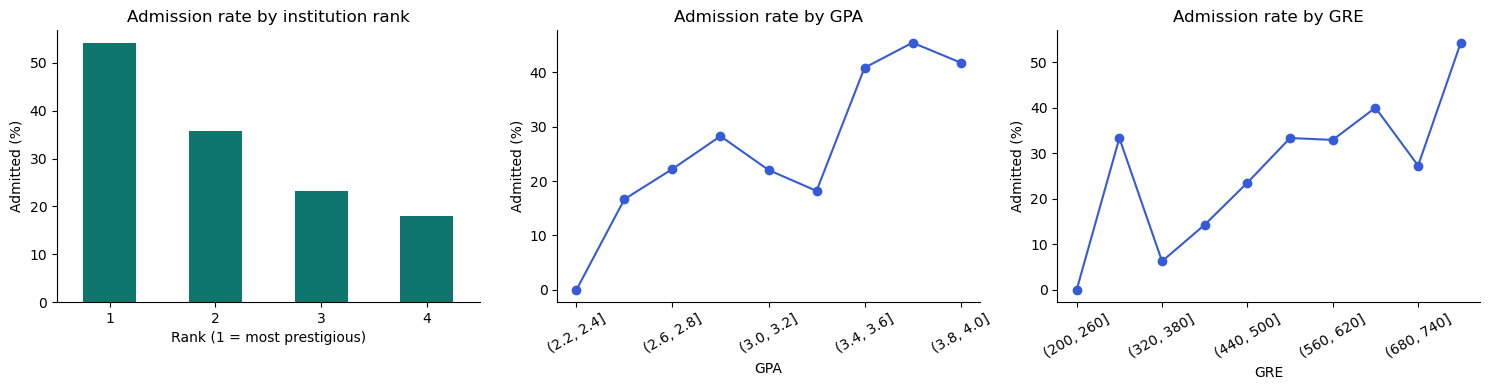

In [2]:
print(f"Overall admission rate: {admissions['admit'].mean():.1%}")
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
admissions.groupby("rank")["admit"].mean().mul(100).plot.bar(ax=axes[0], color=TEAL, rot=0)
axes[0].set(title="Admission rate by institution rank", xlabel="Rank (1 = most prestigious)", ylabel="Admitted (%)")
for ax, col, bins in [(axes[1], "gpa", np.arange(2.2, 4.2, 0.2)), (axes[2], "gre", np.arange(200, 860, 60))]:
    band = pd.cut(admissions[col], bins)
    admissions.groupby(band, observed=True)["admit"].mean().mul(100).plot(ax=ax, marker="o", color=BLUE)
    ax.set(title=f"Admission rate by {col.upper()}", ylabel="Admitted (%)", xlabel=col.upper()); ax.tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.savefig("../images/admission_by_factor.png", dpi=150, bbox_inches="tight"); plt.show()

Admission rates fall steadily from rank-1 to rank-4 institutions and rise with GPA and GRE.

## 2. Interpretable model: logistic regression and odds ratios

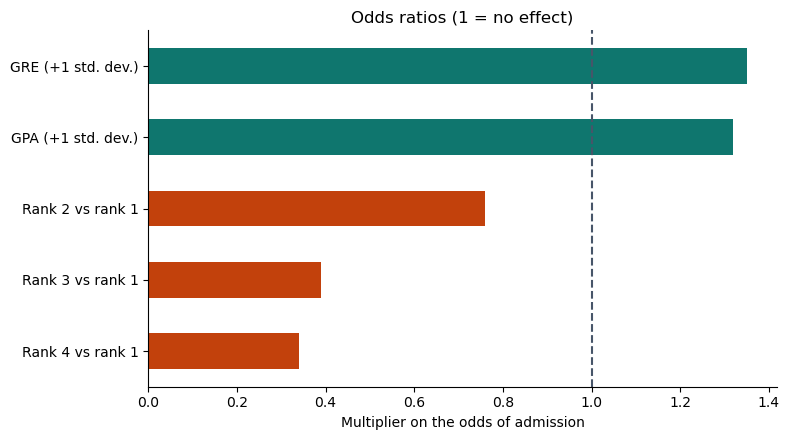

,odds ratio
GRE (+1 std. dev.),1.35
GPA (+1 std. dev.),1.32
Rank 2 vs rank 1,0.76
Rank 3 vs rank 1,0.39
Rank 4 vs rank 1,0.34


In [3]:
X, y = admissions.drop(columns="admit"), admissions["admit"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, stratify=y, random_state=SEED)

prep = ColumnTransformer([("num", StandardScaler(), ["gre", "gpa"]),
                          ("rank", OneHotEncoder(drop="first", categories=[[1, 2, 3, 4]]), ["rank"])])
logit = make_pipeline(prep, LogisticRegression(max_iter=1000)).fit(X_train, y_train)

names = ["GRE (+1 std. dev.)", "GPA (+1 std. dev.)", "Rank 2 vs rank 1", "Rank 3 vs rank 1", "Rank 4 vs rank 1"]
odds = pd.Series(np.exp(logit[-1].coef_[0]), index=names).round(2)
ax = odds.sort_values().plot.barh(color=[ORANGE if v < 1 else TEAL for v in odds.sort_values()])
ax.axvline(1, color="#475569", ls="--"); ax.set(title="Odds ratios (1 = no effect)", xlabel="Multiplier on the odds of admission")
plt.tight_layout(); plt.savefig("../images/odds_ratios.png", dpi=150, bbox_inches="tight"); plt.show()
odds.to_frame("odds ratio")

**Reading the odds ratios:** values above 1 increase the odds of admission, values below 1 decrease them. Coming from a rank-4 institution cuts the odds of admission substantially compared with rank 1, even at the same GRE and GPA.

## 3. Evaluate with cross-validation, then once on the test set

In [4]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
rows = {}
for name, m in {"Baseline (always 'not admitted')": make_pipeline(prep, DummyClassifier(strategy="most_frequent")),
                "Logistic regression": make_pipeline(prep, LogisticRegression(max_iter=1000)),
                "Logistic regression (balanced)": make_pipeline(prep, LogisticRegression(max_iter=1000, class_weight="balanced"))}.items():
    s = cross_validate(m, X_train, y_train, cv=cv, scoring=["accuracy", "precision", "recall", "f1", "roc_auc"])
    rows[name] = {k: s[f"test_{k}"].mean() for k in ["accuracy", "precision", "recall", "f1", "roc_auc"]}
pd.DataFrame(rows).T.round(3)

,accuracy,precision,recall,f1,roc_auc
Baseline (always 'not admitted'),0.683,0.000,0.000,0.000,0.500
Logistic regression,0.687,0.519,0.168,0.251,0.648
Logistic regression (balanced),0.610,0.421,0.642,0.508,0.647


Accuracy alone is misleading here: predicting *not admitted* for everyone already scores about 68%. The default model is accurate but misses most admitted students; class balancing trades some accuracy for much better recall.

Test accuracy 0.630 | precision 0.436 | recall 0.531 | F1 0.479 | ROC-AUC 0.670


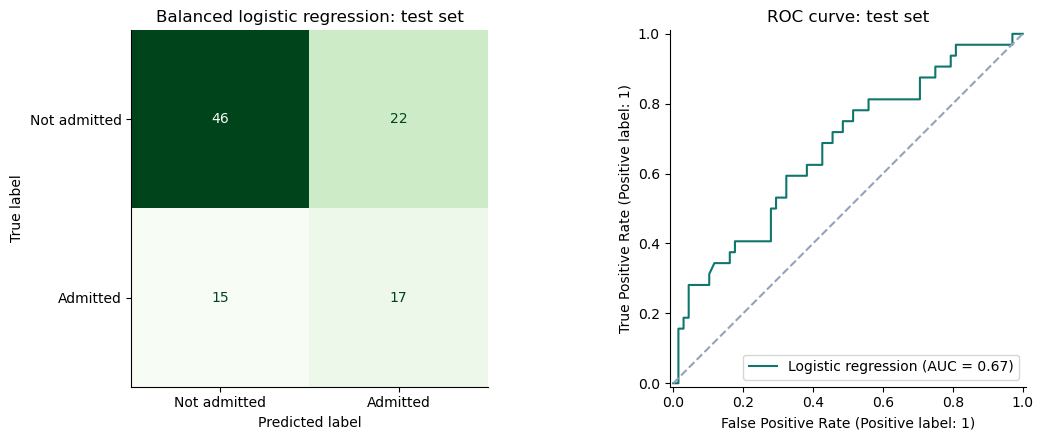

In [5]:
model = make_pipeline(prep, LogisticRegression(max_iter=1000, class_weight="balanced")).fit(X_train, y_train)
proba = model.predict_proba(X_test)[:, 1]; pred = (proba >= 0.5).astype(int)
print(f"Test accuracy {accuracy_score(y_test, pred):.3f} | precision {precision_score(y_test, pred):.3f} | "
      f"recall {recall_score(y_test, pred):.3f} | F1 {f1_score(y_test, pred):.3f} | ROC-AUC {roc_auc_score(y_test, proba):.3f}")
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=["Not admitted", "Admitted"], cmap="Greens", ax=axes[0], colorbar=False)
axes[0].set_title("Balanced logistic regression: test set")
RocCurveDisplay.from_predictions(y_test, proba, ax=axes[1], name="Logistic regression", color=TEAL)
axes[1].plot([0, 1], [0, 1], "--", color="#94a3b8"); axes[1].set_title("ROC curve: test set")
plt.tight_layout(); plt.savefig("../images/test_evaluation.png", dpi=150, bbox_inches="tight"); plt.show()

## 4. Choosing a threshold
If the model were used to **shortlist** applicants for a closer human review, missing a strong applicant (low recall) is worse than reviewing a few extra files.

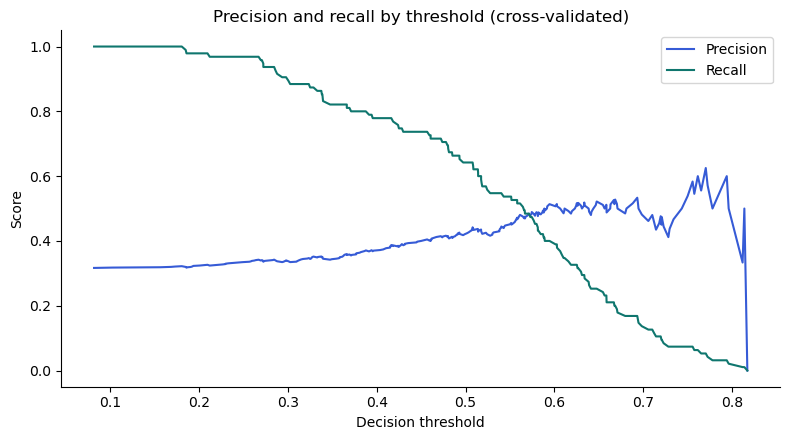

threshold 0.4: precision 0.37 | recall 0.78
threshold 0.5: precision 0.42 | recall 0.64
threshold 0.6: precision 0.51 | recall 0.39


In [6]:
oof = cross_val_predict(make_pipeline(prep, LogisticRegression(max_iter=1000, class_weight="balanced")),
                        X_train, y_train, cv=cv, method="predict_proba")[:, 1]
prec, rec, thr = precision_recall_curve(y_train, oof)
plt.plot(thr, prec[:-1], label="Precision", color=BLUE); plt.plot(thr, rec[:-1], label="Recall", color=TEAL)
plt.xlabel("Decision threshold"); plt.ylabel("Score"); plt.title("Precision and recall by threshold (cross-validated)"); plt.legend()
plt.tight_layout(); plt.savefig("../images/threshold_tradeoff.png", dpi=150, bbox_inches="tight"); plt.show()
for t in [0.4, 0.5, 0.6]:
    p = (oof >= t).astype(int)
    print(f"threshold {t}: precision {precision_score(y_train, p):.2f} | recall {recall_score(y_train, p):.2f}")

## 5. Conclusions, fairness, and limitations
- **Institution rank, GPA, and GRE** all relate to admission, with institution rank having a large effect even after controlling for scores.
- Predictive power is **modest** (ROC-AUC about 0.65 to 0.67): these three variables leave out essays, recommendations, research, and interviews, which drive much of a real decision.
- **Fairness:** institution prestige can encode socioeconomic advantage. A model trained on past decisions would reproduce that bias, so it should support, never replace, human review, and its errors should be audited across groups.
- **Leakage check:** all features are known at application time; no outcome information is used as a predictor.